# Step 2 — Custom CNN (from scratch)
**Oral Diseases Image Classification · Sprint Two**

This is our **baseline**: a CNN built from scratch with no pretrained weights. Every pretrained model in the next steps must beat it to justify itself.

Rules we follow (to avoid the mistakes seen in other write-ups):
- Train on **train**, tune/choose on **val**. The **test** set is **not touched** in this notebook — it is used once, at the very end, for the final comparison.
- Class weights because the classes are imbalanced (Gingivitis 1,236 vs Discoloration 171).
- Augmentation only during training (it is part of the model and switches itself off at prediction time).

**Before running**
1. *Settings → Accelerator → **GPU T4 x2*** (or P100). Without a GPU, training is very slow.
2. *Add Input → Notebooks → Your Work →* pick the **Step 1** notebook (its output holds the clean data).
3. No internet needed in this step.

In [1]:
import os, json, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score

SEED       = 42
IMG_SIZE   = (224, 224)
BATCH      = 32
EPOCHS     = int(os.environ.get("EPOCHS", 40))
SEARCH_ROOT = os.environ.get("DATA_ROOT", "/kaggle/input")
WORK_DIR    = os.environ.get("WORK_DIR", "/kaggle/working")

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# locate the clean dataset produced by Step 1 (the folder that contains manifest.csv)
DATA_DIR = None
for d, _, files in os.walk(SEARCH_ROOT):
    if "manifest.csv" in files and "meta.json" in files:
        DATA_DIR = d; break
assert DATA_DIR, "Step-1 output not found. Add it via: Add Input -> Notebooks -> Your Work"
meta = json.load(open(os.path.join(DATA_DIR, "meta.json")))
CLASS_NAMES = meta["class_names"]
os.makedirs(os.path.join(WORK_DIR, "results"), exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPUs      :", tf.config.list_physical_devices("GPU") or "NONE  <-- turn on the GPU accelerator!")
print("DATA_DIR  :", DATA_DIR)
print("Classes   :", CLASS_NAMES)

TensorFlow: 2.20.0
GPUs      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
DATA_DIR  : /kaggle/input/notebooks/mazenayad/step1-data-cleaning-split/oral_clean
Classes   : ['Calculus', 'Caries', 'Discoloration', 'Gingivitis', 'Hypodontia', 'Mouth_Ulcer']


## 1) Load the data

In [2]:
def make_ds(split, shuffle):
    ds = keras.utils.image_dataset_from_directory(
        os.path.join(DATA_DIR, split), label_mode="categorical", class_names=CLASS_NAMES,
        image_size=IMG_SIZE, batch_size=BATCH, shuffle=shuffle, seed=SEED)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds("train", True)
val_ds   = make_ds("val",   False)       # no shuffle -> predictions line up with labels

# class weights: rare classes count more in the loss
counts = np.array([len(os.listdir(os.path.join(DATA_DIR, "train", c))) for c in CLASS_NAMES])
weights = counts.sum() / (len(counts) * counts)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(weights)}
print(pd.DataFrame({"class": CLASS_NAMES, "train_images": counts, "class_weight": weights.round(2)}).to_string(index=False))

Found 2497 files belonging to 6 classes.


I0000 00:00:1792878683.722009      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792878683.726763      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 498 files belonging to 6 classes.
        class  train_images  class_weight
     Calculus           323          1.29
       Caries           134          3.11
Discoloration           124          3.36
   Gingivitis           876          0.48
   Hypodontia           865          0.48
  Mouth_Ulcer           175          2.38


## 2) Build the model
Four convolution blocks (32 → 64 → 128 → 256 filters), each = 2 × (Conv → BatchNorm → ReLU) + MaxPool, then Global Average Pooling, a Dense layer with Dropout, and a 6-way softmax.

In [3]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x)   # faster-moving running stats -> stable validation early on
        x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_custom_cnn(num_classes=len(CLASS_NAMES), dropout=0.4, dense_units=128):
    inp = keras.Input(shape=IMG_SIZE + (3,))
    x = layers.RandomFlip("horizontal")(inp)            # augmentation: active only in training
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomContrast(0.1)(x)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in (32, 64, 128, 256):
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inp, out, name="custom_cnn")

model = build_custom_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           51

 Total params: 1,208,806 (4.61 MB)

 Trainable params: 1,206,886 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 3) Train

In [4]:
ckpt_path = os.path.join(WORK_DIR, "custom_cnn_best.keras")
callbacks = [
    keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=2)
train_seconds = time.time() - t0
epochs_run = len(history.history["loss"])
print(f"\nTrained {epochs_run} epochs in {train_seconds/60:.1f} min")
pd.DataFrame(history.history).to_csv(os.path.join(WORK_DIR, "results", "custom_cnn_history.csv"), index=False)

Epoch 1/40
79/79 - 69s - 869ms/step - accuracy: 0.3332 - loss: 1.6152 - val_accuracy: 0.5000 - val_loss: 1.3469 - learning_rate: 0.0010
Epoch 2/40
79/79 - 22s - 274ms/step - accuracy: 0.4706 - loss: 1.3883 - val_accuracy: 0.5281 - val_loss: 1.2040 - learning_rate: 0.0010
Epoch 3/40
79/79 - 22s - 274ms/step - accuracy: 0.5326 - loss: 1.2915 - val_accuracy: 0.3614 - val_loss: 1.8432 - learning_rate: 0.0010
Epoch 4/40
79/79 - 22s - 282ms/step - accuracy: 0.5174 - loss: 1.2973 - val_accuracy: 0.5924 - val_loss: 1.0936 - learning_rate: 0.0010
Epoch 5/40
79/79 - 22s - 284ms/step - accuracy: 0.5651 - loss: 1.2030 - val_accuracy: 0.5261 - val_loss: 1.2758 - learning_rate: 0.0010
Epoch 6/40
79/79 - 22s - 284ms/step - accuracy: 0.5979 - loss: 1.1722 - val_accuracy: 0.4438 - val_loss: 1.9297 - learning_rate: 0.0010
Epoch 7/40

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
79/79 - 22s - 281ms/step - accuracy: 0.5939 - loss: 1.1601 - val_accuracy: 0.5542 - val_loss: 1.

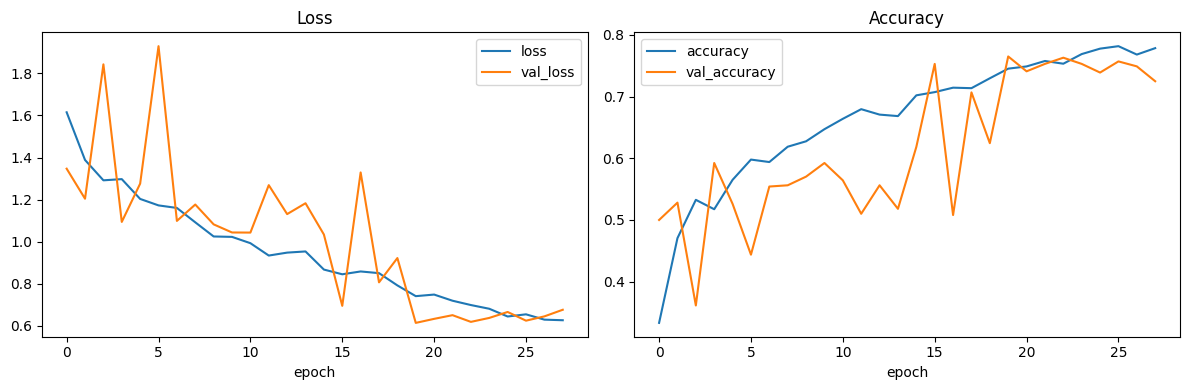

Best epoch (lowest val_loss): 20  | train acc 0.745  | val acc 0.765


In [5]:
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss");      ax[0].set_xlabel("epoch")
h[["accuracy", "val_accuracy"]].plot(ax=ax[1], title="Accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
best = h.val_loss.idxmin()
print(f"Best epoch (lowest val_loss): {best+1}  | train acc {h.accuracy[best]:.3f}  | val acc {h.val_accuracy[best]:.3f}")

## 4) Evaluate on the **validation** set (test set stays untouched)

VALIDATION  accuracy = 0.765   macro-F1 = 0.703

               precision    recall  f1-score   support

     Calculus      0.491     0.871     0.628        62
       Caries      0.500     0.552     0.525        29
Discoloration      0.533     0.667     0.593        24
   Gingivitis      0.908     0.667     0.769       177
   Hypodontia      0.909     0.882     0.896       170
  Mouth_Ulcer      0.871     0.750     0.806        36

     accuracy                          0.765       498
    macro avg      0.702     0.731     0.703       498
 weighted avg      0.812     0.765     0.774       498



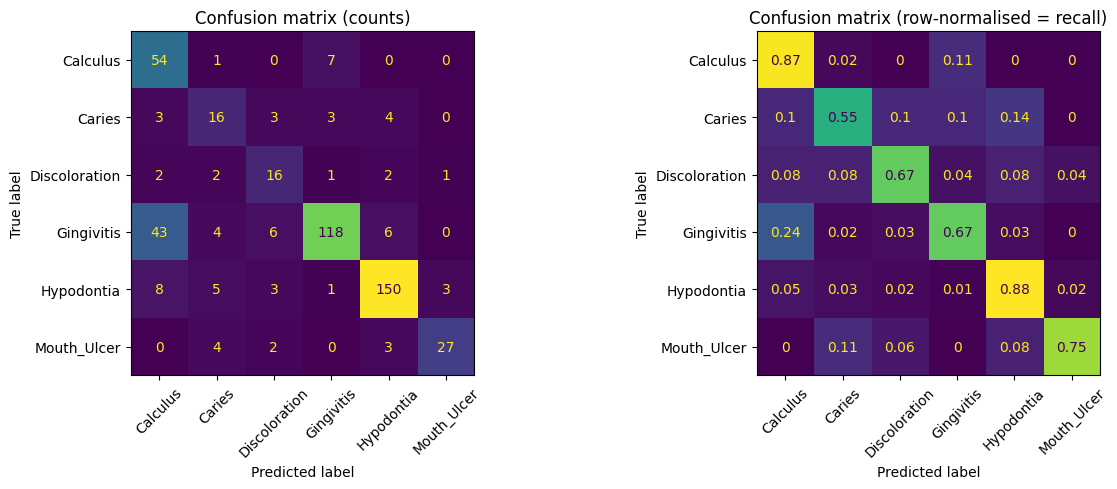

In [6]:
y_true = np.concatenate([y.numpy().argmax(1) for _, y in val_ds])
y_prob = model.predict(val_ds, verbose=0)
y_pred = y_prob.argmax(1)

acc      = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"VALIDATION  accuracy = {acc:.3f}   macro-F1 = {macro_f1:.3f}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASS_NAMES).plot(ax=ax[0], xticks_rotation=45, colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true").round(2), display_labels=CLASS_NAMES).plot(ax=ax[1], xticks_rotation=45, colorbar=False)
ax[1].set_title("Confusion matrix (row-normalised = recall)")
plt.tight_layout(); plt.show()

## 5) Save the results for the final comparison

In [7]:
cm = confusion_matrix(y_true, y_pred)
recall = {c: float(r) for c, r in zip(CLASS_NAMES, cm.diagonal() / cm.sum(1))}
result = {"model": "custom_cnn", "split": "val", "val_accuracy": float(acc), "val_macro_f1": float(macro_f1),
          "per_class_recall": recall, "params": int(model.count_params()),
          "epochs_run": int(epochs_run), "train_minutes": round(train_seconds / 60, 2),
          "best_val_loss": float(h.val_loss.min())}
json.dump(result, open(os.path.join(WORK_DIR, "results", "custom_cnn_val.json"), "w"), indent=2)
print(json.dumps(result, indent=2))

{
  "model": "custom_cnn",
  "split": "val",
  "val_accuracy": 0.7650602409638554,
  "val_macro_f1": 0.7025519853797414,
  "per_class_recall": {
    "Calculus": 0.8709677419354839,
    "Caries": 0.5517241379310345,
    "Discoloration": 0.6666666666666666,
    "Gingivitis": 0.6666666666666666,
    "Hypodontia": 0.8823529411764706,
    "Mouth_Ulcer": 0.75
  },
  "params": 1208806,
  "epochs_run": 28,
  "train_minutes": 11.2,
  "best_val_loss": 0.6133248805999756
}
